In [3]:
# !ffmpeg -y -loglevel error -i audio/noise_recording.m4a -ac 1 -ar 44100 -c:a pcm_s16le audio/noise_recording.wav

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy import signal
import IPython.display as ipd

# Clean Signal

In [10]:
fs_clean, clean_signal = wavfile.read("./audio/clean_speech.wav")
t_clean = np.arange(len(clean_signal)) / fs_clean

print("fs =",fs_clean)
print("Samples =",len(clean_signal))
print("Duration =",len(clean_signal)/fs_clean,"s")
print("signal shape =", clean_signal.shape) #mono signal, 1 channel
print("signal dtype =", clean_signal.dtype)

fs = 16000
Samples = 172343
Duration = 10.7714375 s
signal shape = (172343,)
signal dtype = int16


In [12]:
# int16 can store -32768 to 32767 -> convert to float before adding noise
clean = clean_signal.astype(np.float64)        # step 1: cast to float
clean = clean / np.max(np.abs(clean))          # step 2: peak normalize to [-1, 1]

print(clean.dtype, clean.min(), clean.max())   # should be float64, about -1 to 1

float64 -1.0 0.8294639276324585


Text(0.5, 1.0, 'original clean_signal after peak_normalization')

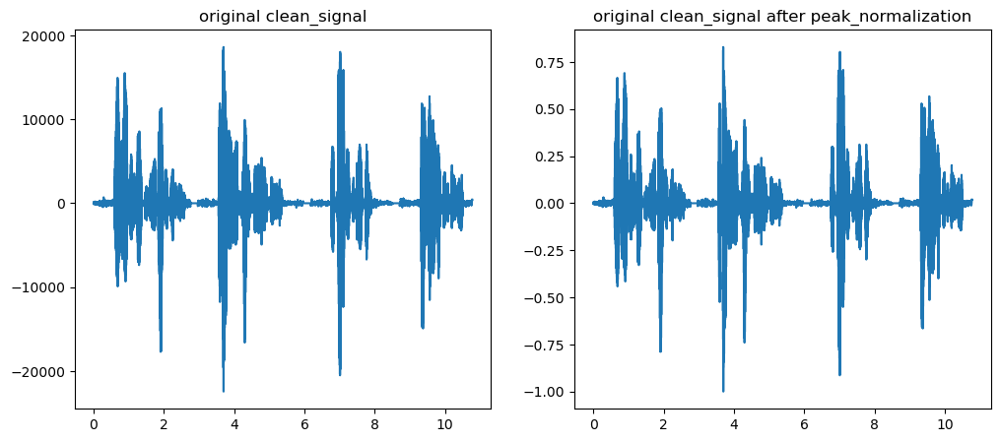

In [19]:
# print(clean)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.plot(t_clean, clean_signal); plt.title("original clean_signal")
plt.subplot(1, 2, 2); plt.plot(t_clean, clean); plt.title("original clean_signal after peak_normalization")

# Noise Signal

In [20]:
fs_noise, noise_signal = wavfile.read("./audio/noise_recording.wav")
t_noise = np.arange(len(noise_signal)) / fs_noise

print("fs =",fs_noise)
print("Samples =",len(noise_signal))
print("Duration =",len(noise_signal)/fs_noise,"s")
print("signal shape =", noise_signal.shape) #mono signal, 1 channel
print("signal dtype =", noise_signal.dtype)

fs = 44100
Samples = 587001
Duration = 13.310680272108844 s
signal shape = (587001,)
signal dtype = int16


In [34]:
noise = noise_signal.astype(np.float64)
noise = noise / np.max(np.abs(noise))

Text(0.5, 1.0, 'original noise_signal after peak_normalization')

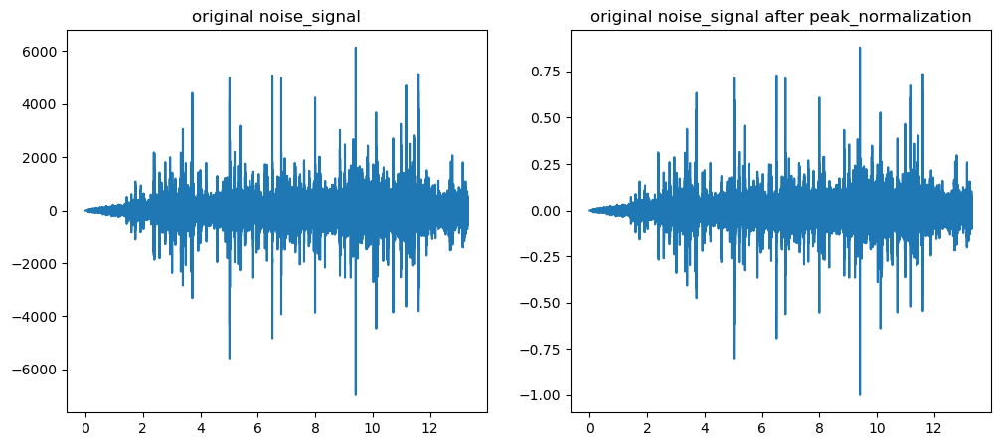

In [35]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.plot(t_noise, noise_signal); plt.title("original noise_signal")
plt.subplot(1, 2, 2); plt.plot(t_noise, noise); plt.title("original noise_signal after peak_normalization")

# Adding noise to clean signal

In [36]:
noise = noise[fs_noise*2:len(clean)+fs_noise*2]
print(len(noise), len(clean))   # both numbers should be the same

172343 172343


In [42]:
noise_level = 0.5               # the number that controls how loud the noise is

noisy_speech = clean + noise_level * noise

Clean


Noisy


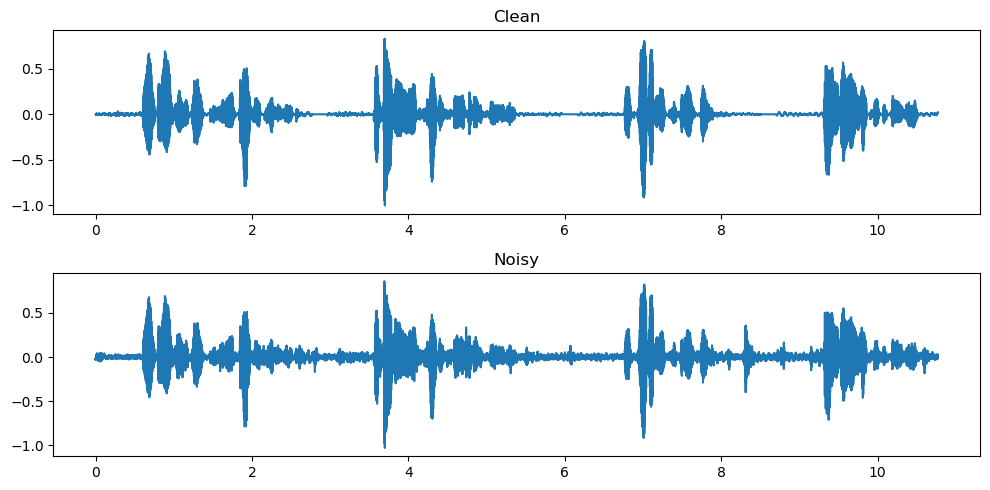

In [43]:
print("Clean")
ipd.display(ipd.Audio(clean, rate=fs_clean))
print("Noisy")
ipd.display(ipd.Audio(noisy_speech, rate=fs_clean))

plt.figure(figsize=(10, 5))
plt.subplot(2, 1, 1); plt.plot(t_clean, clean); plt.title("Clean")
plt.subplot(2, 1, 2); plt.plot(t_clean, noisy_speech); plt.title("Noisy")
plt.tight_layout()
plt.show()

In [47]:
# save the noisy_speech
import os
os.makedirs("./audio/audio_run", exist_ok=True)       # make the folder if it doesn't exist

noisy_save = noisy_speech / max(1, np.max(np.abs(noisy_speech)))   # only shrinks it if it goes above 1
wavfile.write("./audio/audio_run/noisy_speech.wav", fs_clean, (noisy_save * 32767).astype(np.int16))

# Noise Reduction

In [93]:
from scipy.signal import stft, istft

# f = freq, t = time step for each slice, X = complex data value
f, t, X = stft(noisy_speech, fs_clean, nperseg=512)                  # noisy speech
_, _, N = stft(noise_level * noise, fs_clean, nperseg=512)           # the noise added

mag = np.abs(X)        # how strong each frequency is
phase = np.angle(X)    # timing information, we keep this unchanged

Text(0, 0.5, 'magnitude')

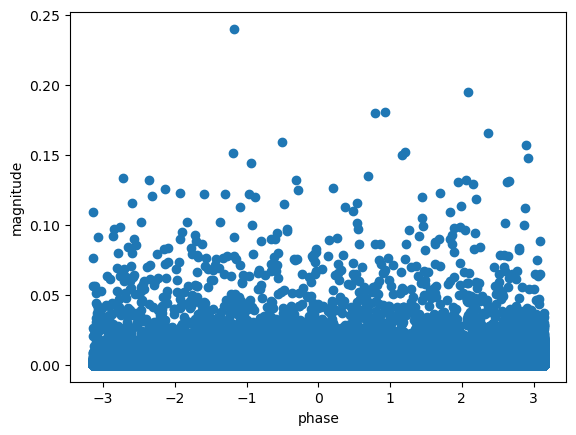

In [94]:
plt.scatter(phase, mag)
plt.xlabel("phase")
plt.ylabel("magnitude")

In [95]:
# noise profile
noise_profile = np.mean(np.abs(N), axis=1, keepdims=True)

In [96]:
alpha = 1.0     # how much noise to subtract (try 1, 2, 3)

clean_mag = np.maximum(mag - alpha * noise_profile, 0.05 * mag)

In [97]:
_, denoised = istft(clean_mag * np.exp(1j * phase), fs_clean, nperseg=512)
denoised = denoised[:len(clean)]        # make it the same length as before

In [98]:
print("Clean");    ipd.display(ipd.Audio(clean, rate=fs_clean))
print("Noisy");    ipd.display(ipd.Audio(noisy_speech, rate=fs_clean))
print("Denoised"); ipd.display(ipd.Audio(denoised, rate=fs_clean))

Clean


Noisy


Denoised


c:\Users\HP\anaconda3\Lib\site-packages\matplotlib\axes\_axes.py:8233: RuntimeWarning: divide by zero encountered in log10
  Z = 10. * np.log10(spec)


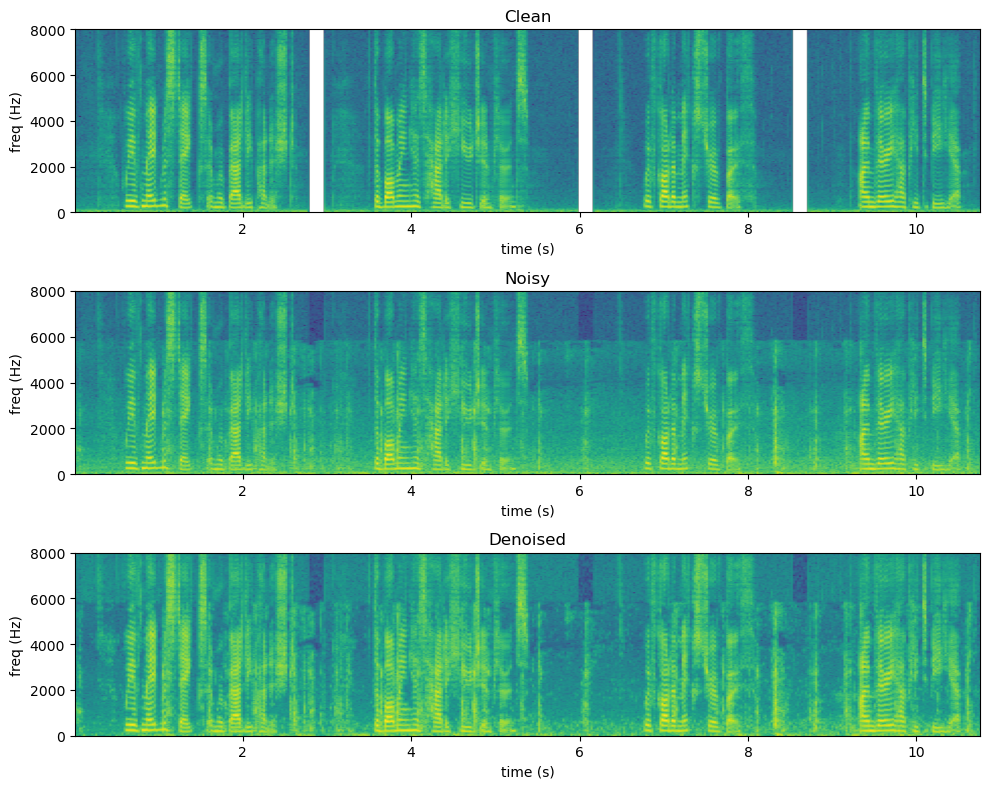

In [99]:
plt.figure(figsize=(10, 8))
for i, (sig, title) in enumerate([(clean, "Clean"), (noisy_speech, "Noisy"), (denoised, "Denoised")]):
    plt.subplot(3, 1, i + 1)
    plt.specgram(sig, Fs=fs_clean, NFFT=512)
    plt.title(title)
    plt.xlabel("time (s)")
    plt.ylabel("freq (Hz)")
plt.tight_layout()
plt.show()

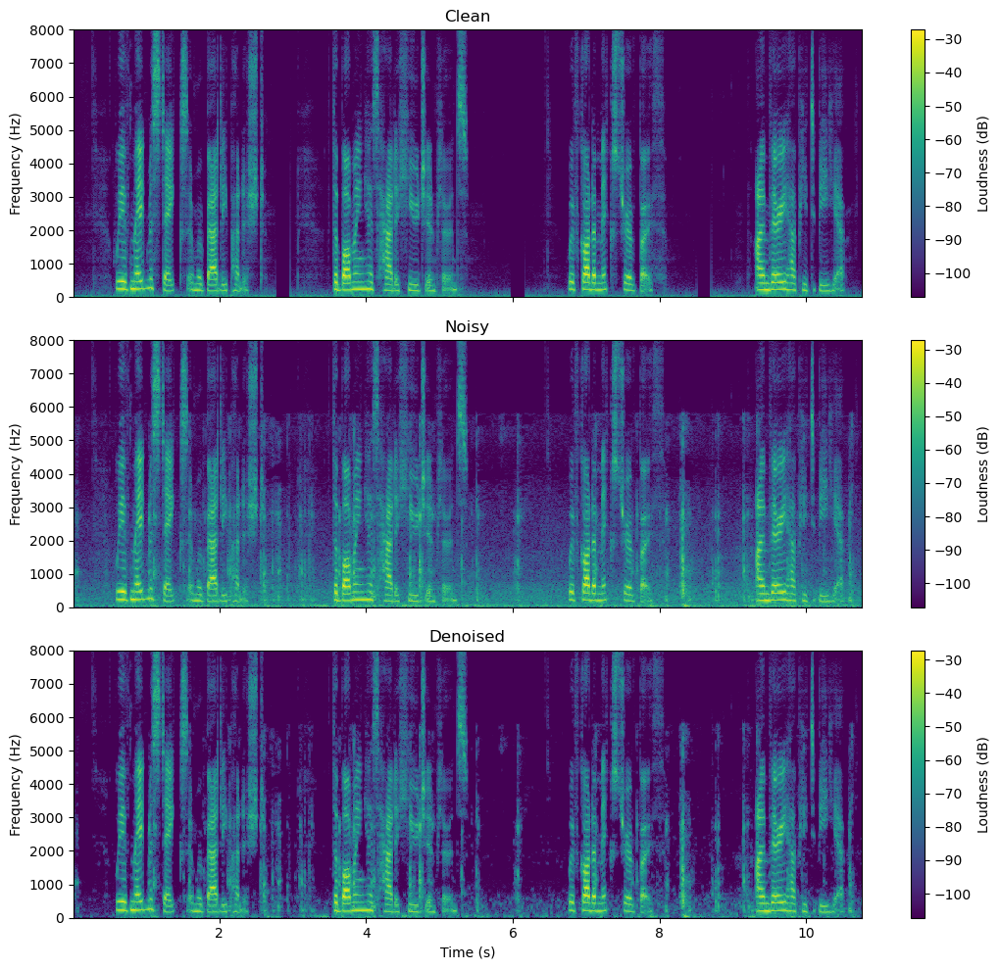

In [100]:
from scipy.signal import spectrogram

def spec_db(sig):
    f, t, S = spectrogram(sig, fs_clean, nperseg=512, noverlap=384)
    return f, t, 10 * np.log10(S + 1e-12)

signals = [("Clean", clean), ("Noisy", noisy_speech), ("Denoised", denoised)]
specs = [spec_db(s) for _, s in signals]

vmax = max(S.max() for _, _, S in specs)     # loudest value in any plot
vmin = vmax - 80                              # show an 80 dB range

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for ax, (title, _), (f, t, S) in zip(axes, signals, specs):
    im = ax.pcolormesh(t, f, S, shading="auto", vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_ylabel("Frequency (Hz)")
    ax.set_ylim(0, 8000)
    fig.colorbar(im, ax=ax, label="Loudness (dB)")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

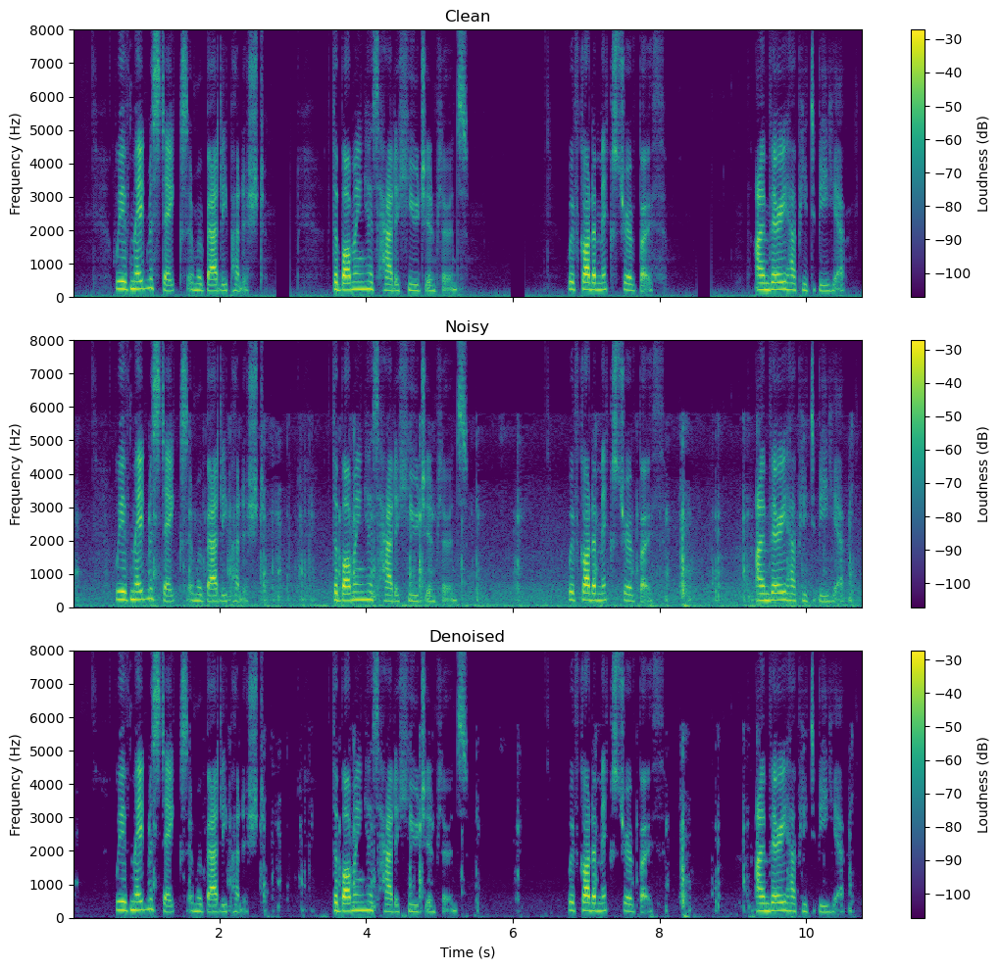

In [101]:
alpha = 2.0     # how much noise to subtract (try 1, 2, 3)
clean_mag = np.maximum(mag - alpha * noise_profile, 0.05 * mag)
_, denoised = istft(clean_mag * np.exp(1j * phase), fs_clean, nperseg=512)
denoised = denoised[:len(clean)]        # make it the same length as before

signals = [("Clean", clean), ("Noisy", noisy_speech), ("Denoised", denoised)]
specs = [spec_db(s) for _, s in signals]

vmax = max(S.max() for _, _, S in specs)     # loudest value in any plot
vmin = vmax - 80                              # show an 80 dB range

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for ax, (title, _), (f, t, S) in zip(axes, signals, specs):
    im = ax.pcolormesh(t, f, S, shading="auto", vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_ylabel("Frequency (Hz)")
    ax.set_ylim(0, 8000)
    fig.colorbar(im, ax=ax, label="Loudness (dB)")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

In [102]:
print("Clean");    ipd.display(ipd.Audio(clean, rate=fs_clean))
print("Noisy");    ipd.display(ipd.Audio(noisy_speech, rate=fs_clean))
print("Denoised"); ipd.display(ipd.Audio(denoised, rate=fs_clean))

Clean


Noisy


Denoised


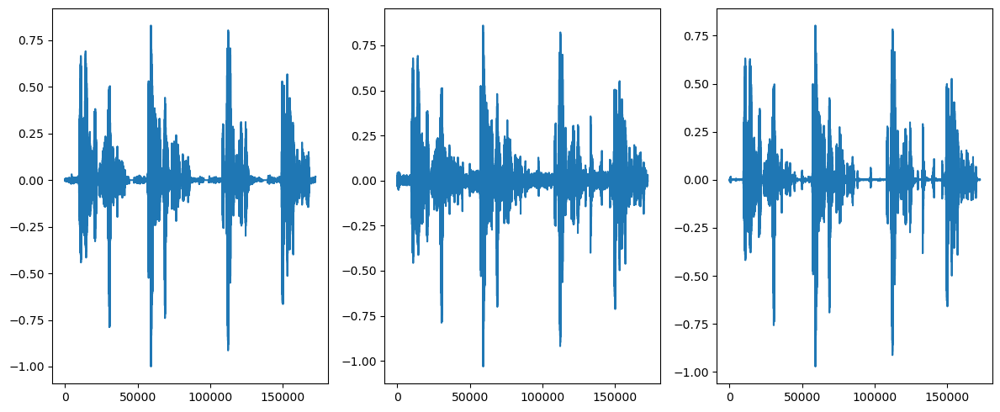

In [103]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1); plt.plot(clean)
plt.subplot(1, 3, 2); plt.plot(noisy_speech)
plt.subplot(1, 3, 3); plt.plot(denoised)

plt.tight_layout()

In [104]:
def spectrum(x, fs, nfft = -1):
    N = len(x)
    if nfft == -1:
        nfft = len(x)
    X = np.fft.fft(x, nfft)
    X = X[:N//2]
    mag = np.abs(X) *2/N
    freq= np.arange(len(mag)) * fs / N
    return freq, mag

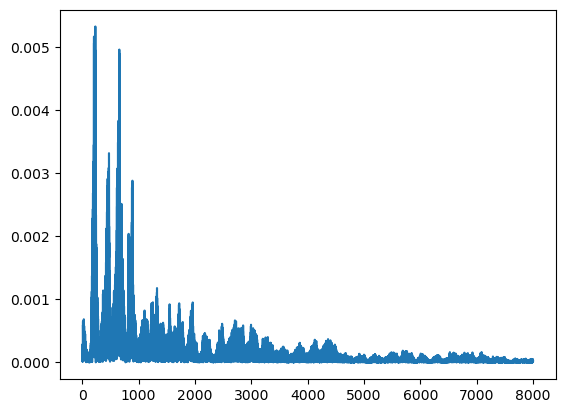

In [105]:
frequency, magnitude = spectrum(denoised, fs_clean)
plt.plot(frequency, magnitude)

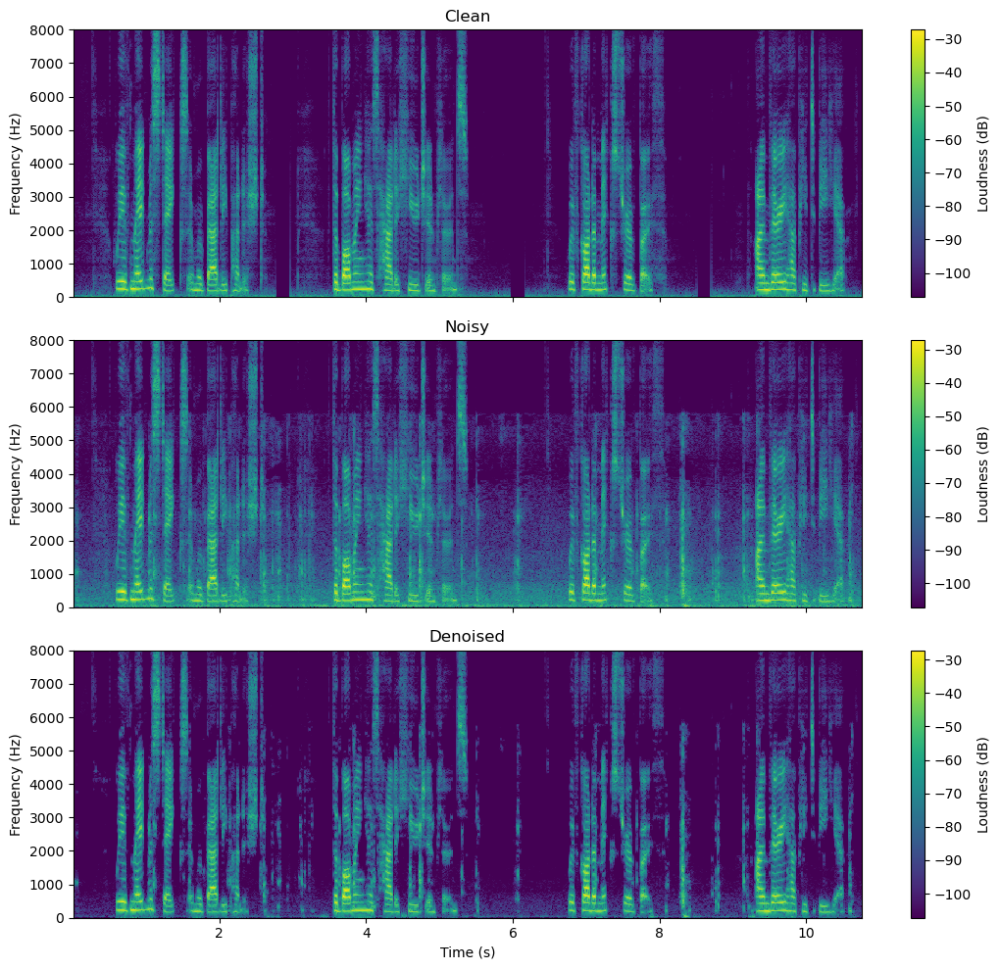

Clean


Noisy


Denoised


In [109]:
alpha = 2.5    # how much noise to subtract (try 1, 2, 3)
clean_mag = np.maximum(mag - alpha * noise_profile, 0.05 * mag)
_, denoised = istft(clean_mag * np.exp(1j * phase), fs_clean, nperseg=512)
denoised = denoised[:len(clean)]        # make it the same length as before

signals = [("Clean", clean), ("Noisy", noisy_speech), ("Denoised", denoised)]
specs = [spec_db(s) for _, s in signals]

vmax = max(S.max() for _, _, S in specs)     # loudest value in any plot
vmin = vmax - 80                              # show an 80 dB range

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for ax, (title, _), (f, t, S) in zip(axes, signals, specs):
    im = ax.pcolormesh(t, f, S, shading="auto", vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_ylabel("Frequency (Hz)")
    ax.set_ylim(0, 8000)
    fig.colorbar(im, ax=ax, label="Loudness (dB)")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()


print("Clean");    ipd.display(ipd.Audio(clean, rate=fs_clean))
print("Noisy");    ipd.display(ipd.Audio(noisy_speech, rate=fs_clean))
print("Denoised"); ipd.display(ipd.Audio(denoised, rate=fs_clean))

In [119]:
from scipy.ndimage import median_filter

# typical level of the neighbors: for each frequency, the middle value over 9 time slices (about 150 ms)
smooth = median_filter(clean_mag, size=(1, 9))

threshold =  8   # a value more than nx its neighbors counts as a click
is_click = clean_mag > threshold * smooth

declicked_mag = np.where(is_click, smooth, clean_mag)   # replace clicks with the neighbor level

print(f"Changed {is_click.mean() * 100:.1f}% of the spectrogram")

_, declicked = istft(declicked_mag * np.exp(1j * phase), fs_clean, nperseg=512)
declicked = declicked[:len(clean)]

print("Spectral subtraction only"); ipd.display(ipd.Audio(denoised, rate=fs_clean))
print("With click removal");        ipd.display(ipd.Audio(declicked, rate=fs_clean))

Changed 7.5% of the spectrogram
Spectral subtraction only


With click removal


# using hci_audio_record.wav to do noise reduction 

In [137]:
fs_real, real_signal = wavfile.read("./hci_audio_record.wav")
real = real_signal.astype(np.float64)
real = real / np.max(np.abs(real))

print(fs_real, len(real), len(real) / fs_real, "s")   # expect 44100 and about 85 s

nper = 512                       # 1024 -  about 23 ms at 44100 Hz
f, t, X = stft(real, fs_real, nperseg=nper)
mag = np.abs(X)
phase = np.angle(X)

# the quietest n% of slices are mostly noise, but skip the first 2 s (fade-in from silence)
energy = mag.sum(axis=0)
valid = t > 2
quiet = valid & (energy <= np.percentile(energy[valid], 50)) #n
noise_profile = mag[:, quiet].mean(axis=1, keepdims=True)

alpha = 1.5 # more noise remove, damage voice
clean_mag = np.maximum(mag - alpha * noise_profile, 0.01 * mag) # after subtracting no value is allow to drop below 0.02

smooth = median_filter(clean_mag, size=(1, 9))
threshold = 5
is_click = clean_mag > threshold * smooth
final_mag = np.where(is_click, smooth, clean_mag)

_, result = istft(final_mag * np.exp(1j * phase), fs_real, nperseg=nper)
result = result[:len(real)]


print("Original");  ipd.display(ipd.Audio(real, rate=fs_real))
print("Denoised");  ipd.display(ipd.Audio(result, rate=fs_real))

44100 3753792 85.12 s
Original


Denoised


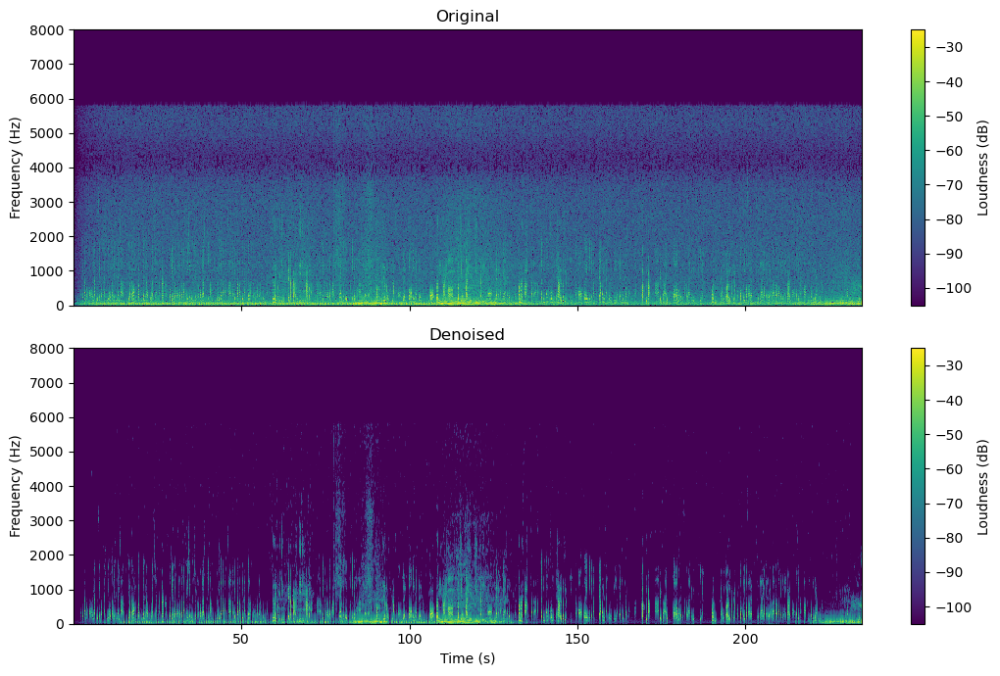

In [138]:
signals = [("Original", real), ("Denoised", result)]
specs = [spec_db(s) for _, s in signals]
vmax = max(S.max() for _, _, S in specs)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, (title, _), (f, t, S) in zip(axes, signals, specs):
    im = ax.pcolormesh(t, f, S, shading="auto", vmin=vmax - 80, vmax=vmax)
    ax.set_title(title); ax.set_ylabel("Frequency (Hz)"); ax.set_ylim(0, 8000)
    fig.colorbar(im, ax=ax, label="Loudness (dB)")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout(); plt.show()

In [140]:
# loudness of each slice, before and after (use the same slices for both)
mag_after = np.abs(stft(result, fs_real, nperseg=nper)[2])

def level_db(m, mask):
    return 20 * np.log10(m[:, mask].mean() + 1e-12)

loud = valid & (energy >= np.percentile(energy[valid], 90))   # loudest 10%: mostly voice

print(f"Quiet parts:  {level_db(mag, quiet):.1f} dB -> {level_db(mag_after, quiet):.1f} dB")
print(f"Loud parts:   {level_db(mag, loud):.1f} dB -> {level_db(mag_after, loud):.1f} dB")

Quiet parts:  -62.8 dB -> -82.4 dB
Loud parts:   -51.8 dB -> -56.2 dB


# another approach

In [142]:
from scipy.signal import butter, sosfiltfilt, firwin, filtfilt
from scipy.ndimage import uniform_filter1d

fs_real, real_signal = wavfile.read("./hci_audio_record.wav")
real = real_signal.astype(np.float64)
real = real / np.max(np.abs(real))

# ---- 1. IIR highpass (Butterworth): removes rumble below the voice ----
sos = butter(4, 70, btype="high", fs=fs_real, output="sos")
x = sosfiltfilt(sos, real)

# ---- 2. FIR lowpass: removes the faint content above the voice ----
fir = firwin(101, 6000, fs=fs_real)        # 101 taps, cutoff 6000 Hz
x = filtfilt(fir, 1.0, x)

# ---- 3. STFT of the filtered signal ----
nper = 512
f, t, X = stft(x, fs_real, nperseg=nper)
mag, phase = np.abs(X), np.angle(X)

# ---- 4. Noise profile, smoothed with a moving average across frequency ----
energy = mag.sum(axis=0)
valid = t > 2
quiet = valid & (energy <= np.percentile(energy[valid], 50))
noise_profile = mag[:, quiet].mean(axis=1, keepdims=True)
noise_profile = uniform_filter1d(noise_profile, size=5, axis=0)

# ---- 5. Spectral subtraction ----
alpha = 1.5
clean_mag = np.maximum(mag - alpha * noise_profile, 0.01 * mag)

# ---- 6. Click detection with a moving average and z-score ----
w = 25                                                   # window in time slices
local_mean = uniform_filter1d(clean_mag, size=w, axis=1)
local_sq = uniform_filter1d(clean_mag**2, size=w, axis=1)
local_std = np.sqrt(np.maximum(local_sq - local_mean**2, 1e-12))
z = (clean_mag - local_mean) / local_std

z_thresh = 3
is_click = z > z_thresh
final_mag = np.where(is_click, local_mean, clean_mag)
print(f"Clicks changed: {is_click.mean() * 100:.1f}%")

# ---- 7. Back to audio ----
_, result = istft(final_mag * np.exp(1j * phase), fs_real, nperseg=nper)
result = result[:len(real)]

print("Original");  ipd.display(ipd.Audio(real, rate=fs_real))
print("Denoised");  ipd.display(ipd.Audio(result, rate=fs_real))

Clicks changed: 0.7%
Original


Denoised


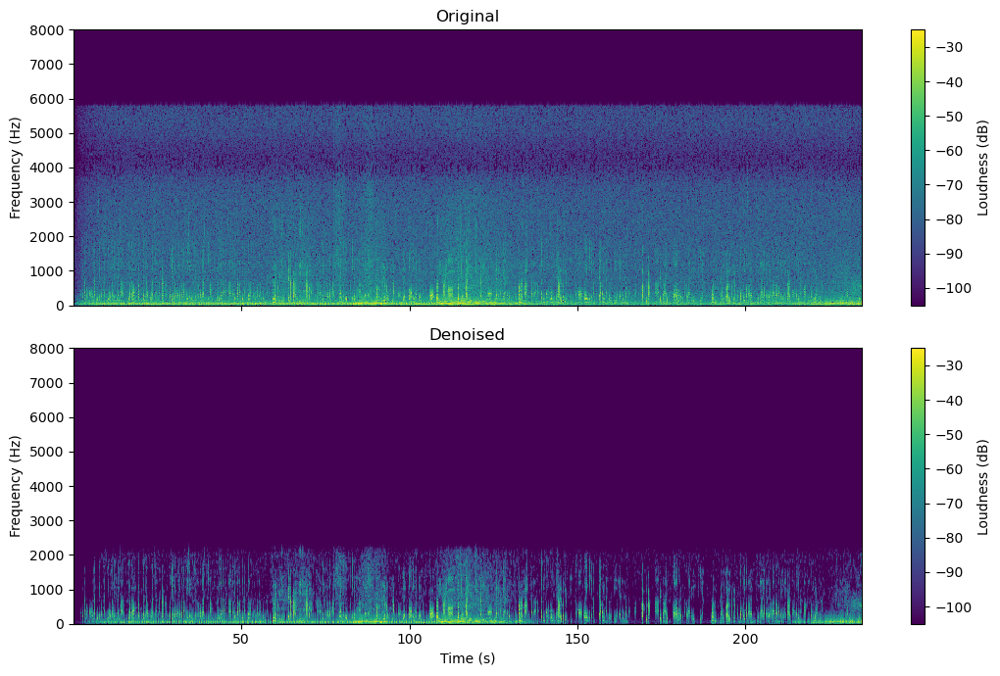

In [143]:
signals = [("Original", real), ("Denoised", result)]
specs = [spec_db(s) for _, s in signals]
vmax = max(S.max() for _, _, S in specs)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, (title, _), (f, t, S) in zip(axes, signals, specs):
    im = ax.pcolormesh(t, f, S, shading="auto", vmin=vmax - 80, vmax=vmax)
    ax.set_title(title); ax.set_ylabel("Frequency (Hz)"); ax.set_ylim(0, 8000)
    fig.colorbar(im, ax=ax, label="Loudness (dB)")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout(); plt.show()